# Attention net flow under expression permutation

How much of the sender → receiver structure that InterScale reads from its attention depends on the spatial arrangement of expression? This notebook tests that on the CosMx human pancreas data of [Melton, Jimenez et al., 2025](https://doi.org/10.5281/zenodo.14870960) (ND and T1D donors).

**Idea.** InterScale's global component attends between the cells of a spatial window. Averaging that attention over all pairs of two cell types gives a directed *net flow* between cell types (sender → receiver). If the flow reflects spatial organisation, scrambling which expression profile sits at which position should erode it. We therefore swap the expression profiles of a growing fraction of cells (0, 10, 20, 50, 80 and 100%) while positions, cell-type labels, data splits and windows stay fixed, train one model per level with identical settings (InterScale's original `CombinedModel`), and compare every level with the unpermuted reference (0%).

**What the notebook produces**

1. Sender × receiver net-flow heatmaps for every permutation level, per condition, and the difference to the reference.
2. The aggregate absolute net flow carried by each cell type against the permutation level (the *partial permutation* curves).

Both are drawn from two small tables, `net_flow_matrices.csv` and `partial_permutation_signal.csv`, which the notebook writes to its results folder. Levels found there are not retrained, so an interrupted run resumes and the figures can be redrawn without a GPU.

**Requirements**

- An AnnData file of the CosMx data with raw integer counts in a layer (`counts`), `obsm["spatial"]`, and the `obs` columns named in the parameter cell: a `train`/`val`/`test` split, cell type, condition, a unique field-of-view id and the two sliding-window partitions the model is trained on.
- A GPU. Training one model per level is the expensive part.
- Environment variables for a headless run, so the notebook needs no editing: `NETFLOW_DATA` (the h5ad file), `NETFLOW_RESULTS` (output folder), optionally `NETFLOW_CONFIG` (a YAML that replaces the model settings) and `NETFLOW_SMOKE=1` (two levels, one epoch, one field of view per section: a quick check that the whole chain runs, whose numbers mean nothing). For example: `jupyter nbconvert --to notebook --execute --ExecutePreprocessor.timeout=-1 net_flow_permutation_cosmx.ipynb`.

## How the net flow is computed

InterScale splits every field of view (FOV) into windows and attends between the cells of a window. For one window, the relevance-weighted attention `A` (entry `A[i, j]`: how much cell `i` attends to cell `j`) is averaged over all pairs of cells of two types. The net flow from a sender type `s` to a receiver type `r` is what `r` attends to `s` minus what `s` attends to `r`, so a positive entry reads "information flows from the row cell type to the column cell type". Each window's matrix is divided by its largest absolute entry, then averaged over the windows of a FOV and over the FOVs of a condition (`interscale.evaluation.net_streams.compute_hierarchical_net_flow`). Flows are therefore relative within a window, not absolute attention.

The model is trained on two window partitions (`SAMPLE_KEYS`), but its attention sequences are built from the windows of one of them. The notebook asks the library which one (`attention_window_key`) and aggregates the flow over exactly those windows.

## Parameters

In [1]:
import os
from pathlib import Path

# Locations. A job script sets them through environment variables, so the notebook is not edited.
DATA_PATH = Path(os.environ.get("NETFLOW_DATA", "cosmx_pancreas.h5ad"))
RESULTS_DIR = Path(os.environ.get("NETFLOW_RESULTS", "net_flow_permutation"))
CONFIG_FILE = os.environ.get("NETFLOW_CONFIG") or None  # optional YAML that replaces the model settings below
SMOKE = os.environ.get("NETFLOW_SMOKE", "0") == "1"  # quick end-to-end check; the numbers mean nothing

# Experiment
LEVELS_PCT = [0, 10, 20, 50, 80, 100]  # % of the permutable cells whose expression profile is swapped; 0 = reference
SHUFFLE_SPLITS = None  # None permutes every cell; ["train", "val"] would leave the test slides untouched
SEED = 42  # draws the permutations and seeds every model
MAX_EPOCHS = 20  # the same fixed budget for every level, no early stopping

# Layers and columns of the AnnData
COUNTS_LAYER = "counts"  # raw integer counts: the matrix that is permuted
LAYER_KEY = "log1p_norm"  # layer the model reads, built from the permuted counts
SPLIT_KEY = "split"
CELL_TYPE_KEY = "cell_type_coarse"
CONDITION_KEY = "condition"
FOV_KEY = "slide_fov"  # unique per field of view (`fov` repeats across slides)
SECTION_KEY = "slide_condition"  # one donor per section; only used to subsample in a smoke run
SAMPLE_KEYS = ["sliding_window_square", "sliding_window_v"]  # the two window partitions the model is trained on

# Smoke run: two levels, one epoch, a single field of view per section
SMOKE_FOVS_PER_SECTION = 1
if SMOKE:
    LEVELS_PCT, MAX_EPOCHS = [0, 100], 1

# Figures: stored in the notebook at FIG_DPI, optionally also written to RESULTS_DIR/figures at SAVE_DPI
FIG_DPI = 100
SAVE_FIGURES = True
SAVE_DPI = 200

## Setup

In [2]:
import warnings

warnings.filterwarnings("ignore")  # first: some dependencies warn while they are imported

import copy
import gc
import json
import logging
import math
import re
import resource
import shutil
import subprocess
import sys
import time
from contextlib import contextmanager
from importlib.metadata import version
from types import SimpleNamespace

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import torch
import yaml
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import interscale
from interscale.config import load_config
from interscale.evaluation.net_streams import compute_hierarchical_net_flow
from interscale.geome_dataloader import GraphAnnDataModule
from interscale.tl import prepare_a2d_dataset, prepare_geome_dataset, set_full_reproducibility
from interscale.tl.self_attn_relevance import SelfAttentionRelevance

logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)
logging.getLogger("spatialdata._logging").setLevel(logging.WARNING)  # squidpy reports the graph of every window group
logging.basicConfig(
    level=logging.INFO, format="%(asctime)s %(message)s", datefmt="%H:%M:%S", stream=sys.stdout, force=True
)
log = logging.getLogger("net_flow")


def source_commit():
    """Short git hash of the interscale checkout that is imported, or 'unknown' if it is not a checkout."""
    root = Path(interscale.__file__).resolve().parents[2]
    try:
        return subprocess.run(
            ["git", "-C", str(root), "rev-parse", "--short", "HEAD"], capture_output=True, text=True, check=True
        ).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return "unknown"


assert LEVELS_PCT == sorted(set(LEVELS_PCT)) and LEVELS_PCT[0] == 0, "LEVELS_PCT must increase and start at 0"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
log.info(
    "interscale %s (commit %s) | torch %s | scanpy %s | anndata %s",
    version("interscale"),
    source_commit(),
    torch.__version__,
    sc.__version__,
    ad.__version__,
)
log.info(
    "device: %s",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU found, training will be very slow",
)
if SMOKE:
    log.info(
        "SMOKE RUN: %d FOV(s) per section, levels %s, %d epoch(s); the numbers mean nothing",
        SMOKE_FOVS_PER_SECTION,
        LEVELS_PCT,
        MAX_EPOCHS,
    )

00:15:53 interscale 0.1.dev260+g5ebc109e8 (commit 662e864) | torch 2.12.1+cu126 | scanpy 1.11.5 | anndata 0.12.18


00:15:53 device: NVIDIA A100 80GB PCIe


## Data and permutation levels

The permutation acts on the **raw counts**: a growing fraction of the permutable cells has its count profile swapped with that of another cell, while coordinates, cell-type labels, splits and windows stay where they are. Normalisation to the median library size and the log transform are applied afterwards, so the model sees a permuted but otherwise ordinarily preprocessed matrix (the log-normalised `X` stored in the file is not used).

The cells permuted at one level are a subset of those permuted at the next, so the levels form a series and not independent draws.

In [3]:
def load_base(path, smoke_fovs=None):
    """Read the AnnData and keep what the permutation levels are built from."""
    adata = sc.read_h5ad(path)
    required = [SPLIT_KEY, CELL_TYPE_KEY, CONDITION_KEY, FOV_KEY, *SAMPLE_KEYS] + ([SECTION_KEY] if smoke_fovs else [])
    missing = [key for key in required if key not in adata.obs]
    if missing:
        raise KeyError(f"obs columns {missing} are missing; available: {sorted(adata.obs.columns)}")
    if "spatial" not in adata.obsm:
        raise KeyError("obsm['spatial'] is missing")
    if smoke_fovs:
        keep = []
        for _, fovs in adata.obs.groupby(SECTION_KEY, observed=True)[FOV_KEY]:
            keep += sorted(fovs.astype(str).unique())[:smoke_fovs]
        adata = adata[adata.obs[FOV_KEY].astype(str).isin(keep).to_numpy()].copy()
    counts = sp.csr_matrix(adata.layers[COUNTS_LAYER] if COUNTS_LAYER else adata.X, dtype=np.float32)
    head = counts.data[:100_000]
    if not np.allclose(head, np.round(head)):
        raise ValueError(
            f"{COUNTS_LAYER or 'X'} holds non-integer values. The permutation needs raw counts: "
            "point COUNTS_LAYER at the layer that has them."
        )
    return SimpleNamespace(
        counts=counts, obs=adata.obs.copy(), var=adata.var[[]].copy(), spatial=np.asarray(adata.obsm["spatial"])
    )


t0 = time.time()
base = load_base(DATA_PATH, SMOKE_FOVS_PER_SECTION if SMOKE else None)
log.info("%s: %d cells x %d genes, read in %.0f s", DATA_PATH.name, *base.counts.shape, time.time() - t0)

windows = pd.DataFrame(
    {key: base.obs.groupby(key, observed=True).size().describe()[["count", "50%", "max"]] for key in SAMPLE_KEYS}
).T.rename(columns={"count": "windows", "50%": "median cells", "max": "largest window"})
MAX_WINDOW = int(windows["largest window"].max())
display(windows.astype(int))
display(pd.crosstab(base.obs[SPLIT_KEY], base.obs[CONDITION_KEY], margins=True).rename_axis(index="cells per split"))

00:15:56 cosmx_pancreas.h5ad: 386727 cells x 979 genes, read in 3 s


,windows,median cells,largest window
sliding_window_square,596,631,1600
sliding_window_v,803,451,1426


condition,ND,T1D,All
cells per split,,,
test,51365,100230,151595
train,61460,47251,108711
val,48614,77807,126421
All,161439,225288,386727


In [4]:
def permutation_orders(splits, levels_pct, seed, shuffle_splits):
    """Row order of the count matrix at every level: row `i` of a level takes the counts of row `order[i]`.

    One fixed shuffling of the permutable cells serves all levels (the first `n` of it are drawn at a level), so the
    cells permuted at one level are contained in the next. The generator is consumed level by level, in the order given.
    """
    rng = np.random.default_rng(seed)
    permutable = np.arange(len(splits)) if shuffle_splits is None else np.flatnonzero(np.isin(splits, shuffle_splits))
    pool = rng.permutation(permutable)
    orders = {}
    for pct in levels_pct:
        order = np.arange(len(splits))
        n_drawn = int(round(pct / 100 * len(pool)))
        if n_drawn >= 2:
            drawn = pool[:n_drawn]
            order[drawn] = rng.permutation(drawn)
        orders[pct] = order
    return orders, len(permutable)


ORDERS, N_PERMUTABLE = permutation_orders(base.obs[SPLIT_KEY].astype(str).to_numpy(), LEVELS_PCT, SEED, SHUFFLE_SPLITS)
SCOPE = "all cells" if SHUFFLE_SPLITS is None else "+".join(SHUFFLE_SPLITS) + " cells"
log.info("permutable cells: %d of %d (%s)", N_PERMUTABLE, base.counts.shape[0], SCOPE)
display(
    pd.DataFrame(
        {
            "% permuted": LEVELS_PCT,
            "profiles swapped": [int((ORDERS[pct] != np.arange(base.counts.shape[0])).sum()) for pct in LEVELS_PCT],
        }
    ).set_index("% permuted")
)


def make_level(base, order):
    """AnnData of one level: permuted counts in `X`, their size-normalised log in the layer the model reads."""
    adata = ad.AnnData(
        X=base.counts[order], obs=base.obs.copy(), var=base.var.copy(), obsm={"spatial": base.spatial.copy()}
    )
    normalised = sc.pp.normalize_total(adata, inplace=False)["X"]  # scanpy's default: the median library size
    adata.layers[LAYER_KEY] = sc.pp.log1p(normalised, copy=True)
    return adata

00:15:57 permutable cells: 386727 of 386727 (all cells)


,profiles swapped
% permuted,
0,0
10,38673
20,77345
50,193363
80,309381
100,386727


## Model configuration

The model is InterScale's original `CombinedModel`: a GCN (local component) and a self-attention transformer (global component), each with its own linear decoder. No model variants are used. Everything not listed in the cell below is the package default, and the effective settings are printed after it. What the analysis depends on is set explicitly:

- **Graph radius 110**, in the pixel units of `obsm["spatial"]` (the CosMx radii examined in the manuscript were 0, 60, 110 and 150). Every window is turned into its own graph, so the graph is built from this radius and not read from the file.
- **No long-range mask.** `long_range_attention` stays at its default, off: the option is not implemented in this version of the package. The transformer therefore attends to every other cell of its window, near neighbours included.
- **A fixed budget with a warm-up that fits it.** `MAX_EPOCHS` epochs without early stopping, the same for every level, so that levels differ only in their data. The learning-rate warm-up is a tenth of the budget: the package default of 20 warm-up epochs would cover the whole run, and the model would never train at the full learning rate. The attention is read from the weights `CombinedModel.train` leaves behind (the last epoch in older versions of the package; newer versions restore the best epoch after the warm-up).
- **`max_seq_len`** is the largest window, so no window is subsampled.

Setting `NETFLOW_CONFIG` to a YAML file replaces the dictionary in the cell below. The notebook then only checks that `max_seq_len` covers the largest window and warns if the learning-rate warm-up is not shorter than the run.

In [5]:
MODEL_CONFIG = {
    "model": {
        "local_component": {"name": "GCN"},
        "global_component": {"name": "self-attn-transformer"},
        "decoder": {"type": "linear", "dual_decoder": True},
    },
    "optim": {
        "seed": SEED,
        "n_epochs": MAX_EPOCHS,  # the length the learning-rate schedule is laid out for
        "lr_warmup": max(1, MAX_EPOCHS // 10),
    },
    "dataset": {
        "name": "cosmx_pancreas_net_flow",
        "prediction_task": "regression",
        "prediction_level": "node",
        "layer_key": LAYER_KEY,
        "sample_key": SAMPLE_KEYS,
        "split_key": SPLIT_KEY,
        "batch_size": 8,  # windows per step
        "spatial_neigbors_kwargs": {"coord_type": "generic", "radius": 110},
    },
}


def build_config():
    """The inline settings, or the YAML in CONFIG_FILE, with `max_seq_len` taken from the data."""
    config = yaml.safe_load(Path(CONFIG_FILE).read_text()) if CONFIG_FILE else copy.deepcopy(MODEL_CONFIG)
    parameters = config.setdefault("model", {}).setdefault("global_component", {}).setdefault("parameters", {})
    if CONFIG_FILE and parameters.get("max_seq_len", 0) < MAX_WINDOW:
        raise ValueError(
            f"model.global_component.parameters.max_seq_len must be at least {MAX_WINDOW}, the largest window"
        )
    if not CONFIG_FILE:
        parameters["max_seq_len"] = MAX_WINDOW
    return config


CONFIG_DICT = build_config()
CONFIG_PATH = RESULTS_DIR / "config_used.yaml"
CONFIG_PATH.write_text(yaml.safe_dump(CONFIG_DICT, sort_keys=False))
cfg = load_config(CONFIG_PATH)
assert cfg.dataset.layer_key == LAYER_KEY, "dataset.layer_key must name the layer the notebook builds (LAYER_KEY)"
if cfg.optim.lr_warmup >= MAX_EPOCHS:
    log.warning(
        "optim.lr_warmup is %d epochs but a run has %d: the learning rate never reaches its full value",
        cfg.optim.lr_warmup,
        MAX_EPOCHS,
    )
# The masking fraction is `dataset.mask_percentage` in current versions of the package and `dataset.pct_mask_nodes` in older ones;
# the data module's argument has the same name as the config key in both.
MASK_KEY = "mask_percentage" if "mask_percentage" in cfg.dataset else "pct_mask_nodes"
missing = [key for key in cfg.dataset.sample_key if key not in base.obs]
assert not missing, f"sample keys {missing} are not columns of obs"

display(
    pd.Series(
        {
            "embedding size": cfg.model.n_embed,
            "local component": f"{cfg.model.local_component.name} {dict(cfg.model.local_component.parameters)}",
            "global component": f"{cfg.model.global_component.name} {dict(cfg.model.global_component.parameters)}",
            "loss": cfg.optim.loss,
            "learning rate / warm-up epochs": f"{cfg.optim.lr} / {cfg.optim.lr_warmup}",
            "epochs (fixed)": MAX_EPOCHS,
            "windows per step": cfg.dataset.batch_size,
            "share of cells masked": cfg.dataset[MASK_KEY],
            "graph radius": cfg.dataset.spatial_neigbors_kwargs.radius,
            "seed": cfg.optim.seed,
        },
        name="setting",
    ).to_frame()
)

,setting
embedding size,16
local component,"GCN {'hidden_dim': 256, 'num_layers': 2, 'drop..."
global component,"self-attn-transformer {'n_heads': 4, 'dim_feed..."
loss,GaussianNLL
learning rate / warm-up epochs,0.001 / 2
epochs (fixed),20
windows per step,8
share of cells masked,0.2
graph radius,110
seed,42


## One model per level, and its net flow

`train_and_attend` is the only place a model is touched. It trains a `CombinedModel` on one level, reads the relevance-weighted attention of every window after training and keeps nothing but that matrix and the columns the flow hierarchy needs, so a level's count matrix and model are freed before the next one starts. Two things in the package would otherwise keep them, and both are handled here without changing the attention values: the relevance computation leaves one autograd graph per window that Python's garbage collector cannot free (`relevance_without_graph`), and the model classes keep every AnnData they were set up with (`release_level`). Left alone, memory grows with every level until the job is killed. After every level the flow matrices are written to `net_flow_matrices.csv`; levels already in that file (made with exactly the same settings) are loaded instead of retrained.

In [6]:
def level_config(cfg, pct):
    """A copy of the config that saves this level's checkpoint in a folder of its own."""
    level = cfg.clone()
    level.defrost()
    folder = RESULTS_DIR / "checkpoints" / f"level_{pct:03d}"
    shutil.rmtree(
        folder, ignore_errors=True
    )  # only a level being trained gets here: its folder is left from a failed run
    folder.mkdir(parents=True)
    level.model.save = f"{folder}/"  # the package appends file names to this string
    level.freeze()
    return level


def attention_window_key(cfg, adata):
    """The sample key whose windows `get_model_output` turns into attention sequences.

    The library builds the sequences from one of the sample keys (the first one, at the time of writing). Instead of assuming
    that, this builds the same graphs on a few FOVs and picks the key whose windows they match in size, so a flow is never
    aggregated over windows other than the ones the attention is indexed by.
    """
    fovs = adata.obs[FOV_KEY].astype(str).unique()[:3]
    part = adata[adata.obs[FOV_KEY].astype(str).isin(fovs).to_numpy()].copy()
    graphs, _ = list(prepare_a2d_dataset(cfg)(part))
    sizes = sorted(int(graph.num_nodes) for graph in graphs)
    matches = [key for key in cfg.dataset.sample_key if sorted(part.obs.groupby(key, observed=True).size()) == sizes]
    if len(matches) != 1:
        raise RuntimeError(
            f"cannot tell which sample key the attention sequences follow (window sizes match {matches})"
        )
    return matches[0]


@contextmanager
def relevance_without_graph():
    """Compute the relevance without recording it for autograd.

    `SelfAttentionRelevance.generate_relevance` updates its matrix in place from maps that still require gradients. That makes
    the matrix part of its own autograd graph: a reference cycle inside torch, invisible to Python's garbage collector, that
    keeps each window's whole graph alive. Nothing differentiates the relevance, so detaching the maps gives the same values.
    """
    avg_heads = SelfAttentionRelevance.avg_heads
    SelfAttentionRelevance.avg_heads = staticmethod(lambda attn_map, grad: avg_heads(attn_map.detach(), grad.detach()))
    try:
        yield
    finally:
        SelfAttentionRelevance.avg_heads = staticmethod(avg_heads)


def release_level(model):
    """Drop what outlives a model: the class-level AnnData stores and the attention the layers keep of the last window."""
    type(model)._setup_adata_manager_store.clear()
    type(model)._per_instance_manager_store.clear()
    for module in model.module.modules():
        for name in ("attn_output", "attn_output_weights", "attn_gradients"):
            if hasattr(module, name):
                setattr(module, name, None)


def train_and_attend(adata, cfg):
    """Train on one level; return the attention matrix with its obs columns, and a training summary."""
    set_full_reproducibility(cfg.optim.seed)  # initial weights must not depend on how many levels ran before
    interscale.model.CombinedModel._setup_anndata(
        adata=adata,
        prediction_task=cfg.dataset.prediction_task,
        layer_key=cfg.dataset.layer_key,
        sample_key_list=list(cfg.dataset.sample_key),
        split_key=cfg.dataset.split_key,
        view_registry=False,  # the registry table lists every window
    )
    model = interscale.model.CombinedModel(adata, cfg=cfg)
    graphs, _ = prepare_geome_dataset(adata, cfg)
    datamodule = GraphAnnDataModule(
        datas=graphs,
        num_workers=1,
        batch_size=int(cfg.dataset.batch_size),
        learning_type="node",
        **{MASK_KEY: cfg.dataset[MASK_KEY]},
    )
    window_key = attention_window_key(cfg, adata)  # before training: a mismatch should fail in seconds, not after hours
    model.train(
        max_epochs=MAX_EPOCHS,
        datamodule=datamodule,
        early_stopping=False,
        wandb_use=False,
        enable_progress_bar=False,
        enable_model_summary=False,
    )
    model.module.eval()  # get_model_output leaves dropout on otherwise
    with relevance_without_graph():
        result = model.get_model_output(adata)  # writes the attention into `adata` and hands it back
    keep = list(dict.fromkeys([FOV_KEY, CELL_TYPE_KEY, CONDITION_KEY, window_key]))
    lean = ad.AnnData(obs=result.obs[keep].copy(), obsm={"_attn_matrix": result.obsm["_attn_matrix"]})

    history = pd.DataFrame(model.history_.history)
    losses = [column for column in history.columns if "loss" in column]
    summary = {
        "window_key": window_key,
        "train_windows": len(graphs[0]),
        "steps_per_epoch": math.ceil(len(graphs[0]) / int(cfg.dataset.batch_size)),
        "epochs": int(
            history["train_loss"].notna().sum()
        ),  # the final validation and test passes add rows of their own
        **{f"last_{column}": float(history[column].dropna().iloc[-1]) for column in losses},
    }
    if "val_loss" in history:
        summary["best_val_loss"] = float(history["val_loss"].min())
    release_level(model)
    del model, datamodule, graphs, result
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return lean, summary


def net_flows(lean, window_key):
    """Per condition, the sender x receiver `mean` net flow and its across-FOV `std`, for one level."""
    return compute_hierarchical_net_flow(
        lean,
        window_key=window_key,
        sample_key=FOV_KEY,
        condition_key=CONDITION_KEY,
        cell_type_col=CELL_TYPE_KEY,
        compute_net=True,
    )

In [7]:
def flow_rows(pct, flows):
    """Long-form rows of one level's flow matrices."""
    return [
        {
            "level_pct": pct,
            "condition": str(condition),
            "sender": sender,
            "receiver": receiver,
            "net_flow": float(matrices["mean"].loc[sender, receiver]),
            "net_flow_std": float(matrices["std"].loc[sender, receiver]),
        }
        for condition, matrices in flows.items()
        for sender in matrices["mean"].index
        for receiver in matrices["mean"].columns
    ]


def flows_from_rows(rows):
    """The inverse of `flow_rows`: flows[level][condition] holds the `mean` and `std` DataFrames."""
    flows = {}
    for (pct, condition), part in rows.groupby(["level_pct", "condition"]):
        flows.setdefault(int(pct), {})[condition] = {
            "mean": part.pivot(index="sender", columns="receiver", values="net_flow"),
            "std": part.pivot(index="sender", columns="receiver", values="net_flow_std"),
        }
    return flows


def cell_type_signal(mean):
    """Aggregate absolute net flow a cell type carries as sender and as receiver (halved: each flow is counted twice)."""
    absolute = np.abs(mean.to_numpy(dtype=float))
    return pd.Series((np.nansum(absolute, axis=0) + np.nansum(absolute, axis=1)) / 2, index=mean.index)


FLOW_CSV = RESULTS_DIR / "net_flow_matrices.csv"
SUMMARY_CSV = RESULTS_DIR / "training_summary.csv"
SETTINGS_JSON = RESULTS_DIR / "run_settings.json"
# What a level's result depends on. Saved levels are reused only when this is identical.
SETTINGS = json.loads(
    json.dumps(
        {
            "data_file": DATA_PATH.name,
            "n_cells": int(base.counts.shape[0]),
            "counts_layer": COUNTS_LAYER,
            "shuffle_splits": SHUFFLE_SPLITS,
            "seed": SEED,
            "max_epochs": MAX_EPOCHS,
            "fov_key": FOV_KEY,
            "cell_type_key": CELL_TYPE_KEY,
            "condition_key": CONDITION_KEY,
            "model_config": CONFIG_DICT,
            "smoke": SMOKE,
        }
    )
)


def read_saved_levels():
    """Flows and training summaries already on disk; empty on a fresh results folder."""
    if not SETTINGS_JSON.exists() or not FLOW_CSV.exists():
        return {}, pd.DataFrame()
    saved = json.loads(SETTINGS_JSON.read_text())
    if saved != SETTINGS:
        changed = sorted(key for key in SETTINGS if saved.get(key) != SETTINGS[key])
        raise RuntimeError(
            f"{RESULTS_DIR.name} holds results made with other settings ({', '.join(changed)}). "
            "Use a new results folder, or delete this one to start again."
        )
    summaries = pd.read_csv(SUMMARY_CSV) if SUMMARY_CSV.exists() else pd.DataFrame()
    return flows_from_rows(pd.read_csv(FLOW_CSV)), summaries

### Run all levels

Each level takes the permuted counts, trains a model, reads its attention and reduces it to the cell-type flow matrices. The log shows the number of training windows and optimiser steps per epoch, which is the model's real training budget.

In [8]:
flows, saved_summaries = read_saved_levels()
summaries = saved_summaries.to_dict("records")
rows = [row for pct, by_condition in flows.items() for row in flow_rows(pct, by_condition)]
SETTINGS_JSON.write_text(json.dumps(SETTINGS, indent=1))

for pct in LEVELS_PCT:
    if pct in flows:
        log.info("level %d%%: loaded from %s, not retrained", pct, FLOW_CSV.name)
        continue
    started = time.time()
    adata = make_level(base, ORDERS[pct])
    log.info("level %d%%: training", pct)
    lean, summary = train_and_attend(adata, level_config(cfg, pct))
    del adata
    gc.collect()
    log.info(
        "level %d%%: %d training windows, %d steps per epoch; aggregating the net flow over the windows of %s",
        pct,
        summary["train_windows"],
        summary["steps_per_epoch"],
        summary["window_key"],
    )
    flows[pct] = net_flows(lean, summary["window_key"])
    del lean
    gc.collect()
    rows += flow_rows(pct, flows[pct])
    summaries.append({"level_pct": pct, **summary, "minutes": round((time.time() - started) / 60, 1)})
    # written after every level, so an interrupted run keeps the finished ones
    pd.DataFrame(rows).to_csv(FLOW_CSV, index=False)
    pd.DataFrame(summaries).to_csv(SUMMARY_CSV, index=False)
    peak_gb = (
        resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2
    )  # stays flat across levels unless memory leaks
    log.info("level %d%%: done in %.1f min, peak RAM so far %.0f GB", pct, (time.time() - started) / 60, peak_gb)

display(pd.DataFrame(summaries).sort_values("level_pct").set_index("level_pct").round(4))

00:15:58 level 0%: loaded from net_flow_matrices.csv, not retrained


00:15:58 level 10%: loaded from net_flow_matrices.csv, not retrained


00:15:58 level 20%: loaded from net_flow_matrices.csv, not retrained


00:15:58 level 50%: loaded from net_flow_matrices.csv, not retrained


00:16:11 level 80%: training


Load GEX from .layers/log1p_norm


... (24 outputs left out)

Model checkpoint will be saved in:  net_flow_permutation/checkpoints/level_100/dual_cosmx_pancreas_net_flow_regr_node_42_GCN_self-attn-transformer_model.ckpt
Load GEX from .layers/log1p_norm


00:24:24 level 100%: 466 training windows, 59 steps per epoch; aggregating the net flow over the windows of sliding_window_square


00:24:42 level 100%: done in 4.0 min, peak RAM so far 16 GB


,window_key,train_windows,steps_per_epoch,epochs,last_val_local_loss,last_val_global_loss,last_val_loss,last_train_local_loss,last_train_global_loss,last_train_loss,last_test_local_loss,last_test_global_loss,last_test_loss,best_val_loss,minutes
level_pct,,,,,,,,,,,,,,,
0,sliding_window_square,466,59,21,NaN,NaN,NaN,NaN,NaN,NaN,-0.5297,-0.5297,-0.5297,-0.5303,4.4
10,sliding_window_square,466,59,21,NaN,NaN,NaN,NaN,NaN,NaN,-0.5312,-0.5312,-0.5312,-0.5302,3.5
20,sliding_window_square,466,59,21,NaN,NaN,NaN,NaN,NaN,NaN,-0.5322,-0.5323,-0.5323,-0.5305,3.8
50,sliding_window_square,466,59,21,NaN,NaN,NaN,NaN,NaN,NaN,-0.5313,-0.5314,-0.5314,-0.5328,3.9
80,sliding_window_square,466,59,20,-0.5328,-0.5329,-0.5329,-0.5331,-0.5322,-0.5327,-0.5331,-0.5333,-0.5332,-0.5329,4.8
100,sliding_window_square,466,59,20,-0.5319,-0.5320,-0.5319,-0.5332,-0.5322,-0.5327,-0.5346,-0.5348,-0.5347,-0.5319,4.0


## Net flow by permutation level

One figure per condition. Each panel is the sender (rows) × receiver (columns) net-flow matrix of one permutation level, and all panels of a figure share one symmetric colour scale, so a fading colour means a fading flow. Red marks net flow from the row cell type to the column cell type and blue the opposite direction. The matrix is antisymmetric: every pair appears twice, with opposite sign.

In [9]:
# Chart chrome and colours, shared by all figures below.
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
# Diverging blue <-> red with a neutral midpoint and matching lightness steps on both arms: the direction of a flow.
FLOW_CMAP = LinearSegmentedColormap.from_list(
    "flow_diverging", ["#0d366b", "#256abf", "#9ec5f4", "#f0efec", "#f2a3a2", "#d03b3b", "#6e1817"]
)
# The two conditions take the first two slots of a categorical palette that stays separable under colour-vision
# deficiency. A condition keeps its colour whichever conditions are shown.
CONDITION_COLORS = {"ND": "#2a78d6", "T1D": "#eb6834"}
SPARE_COLORS = ["#1baf7a"]
EPS = 1e-9  # keeps a z-score finite where a flow is identical in every FOV
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "sans-serif",
        "text.color": INK,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
    }
)


def slug(text):
    """A condition name reduced to something safe to put in a file name."""
    return re.sub(r"[^0-9A-Za-z._-]+", "_", str(text)).strip("_") or "unnamed"


def condition_colors(conditions):
    """One colour per condition: the fixed ones where known, then spare slots (three conditions at most)."""
    spare = iter(SPARE_COLORS)
    colors = {}
    for condition in conditions:
        colors[condition] = CONDITION_COLORS.get(condition) or next(spare, None)
        if colors[condition] is None:
            raise ValueError("more than three conditions cannot be told apart by colour here")
    return colors


def ink_on(rgba):
    """White or near-black, whichever reads better on a fill."""
    linear = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    return "#ffffff" if 0.2126 * linear[0] + 0.7152 * linear[1] + 0.0722 * linear[2] < 0.18 else INK


def significance_marks(z):
    """'*', '**' or '***' where |z| passes 1.96, 2.58 or 3.29 (a normal approximation); blank elsewhere."""
    size = np.abs(z.to_numpy(dtype=float))
    marks = np.where(size >= 3.29, "***", np.where(size >= 2.58, "**", np.where(size >= 1.96, "*", "")))
    return pd.DataFrame(marks, index=z.index, columns=z.columns)


def draw_matrix(ax, matrix, limit, marks=None):
    """Draw a sender x receiver matrix on a symmetric colour scale; `marks` holds a short text per cell."""
    values = np.ma.masked_invalid(matrix.to_numpy(dtype=float))
    n_rows, n_cols = values.shape
    mesh = ax.pcolormesh(values, cmap=FLOW_CMAP, vmin=-limit, vmax=limit, edgecolors=SURFACE, linewidth=1.2)
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_aspect("equal")
    ax.set_xticks(
        np.arange(n_cols) + 0.5, matrix.columns, rotation=60, ha="right", rotation_mode="anchor", fontsize=7.5
    )
    ax.set_yticks(np.arange(n_rows) + 0.5, matrix.index, fontsize=7.5)
    ax.set_xlabel("Receiver", fontsize=8.5)
    ax.set_ylabel("Sender", fontsize=8.5)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    if marks is not None:
        for i, j in zip(*np.nonzero(marks.to_numpy(dtype=str) != ""), strict=False):
            ax.text(
                j + 0.5,
                i + 0.5,
                marks.iat[i, j],
                ha="center",
                va="center",
                fontsize=7,
                color=ink_on(mesh.cmap(mesh.norm(values[i, j]))),
            )
    return mesh


def plot_matrix_grid(panels, limit, colorbar_label, title, note):
    """Panels of (title, matrix, marks) on a grid of three columns that share one colour scale and one colour bar."""
    n_cols = 3
    n_rows = math.ceil(len(panels) / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3.6 * n_cols + 1.0, 3.4 * n_rows + 1.1),
        dpi=FIG_DPI,
        layout="constrained",
        squeeze=False,
    )
    for ax, (panel_title, matrix, marks) in zip(axes.ravel(), panels, strict=False):
        mesh = draw_matrix(ax, matrix, limit, marks)
        ax.set_title(panel_title, loc="left", fontsize=10, fontweight="bold", color=INK)
    for ax in axes.ravel()[len(panels) :]:
        ax.set_visible(False)
    bar = fig.colorbar(mesh, ax=axes, shrink=0.55, pad=0.02, aspect=22)
    bar.set_label(colorbar_label, color=INK_2, fontsize=9)
    bar.outline.set_visible(False)
    bar.ax.tick_params(length=0, labelsize=8, colors=INK_2)
    fig.suptitle(title, x=0.0, ha="left", fontsize=12, fontweight="bold")
    fig.supxlabel(note, x=0.0, ha="left", fontsize=8.5, color=INK_2)
    return fig


def show(fig, name):
    """Show a figure in the notebook, write it to RESULTS_DIR/figures if asked, and close it."""
    if SAVE_FIGURES:
        (RESULTS_DIR / "figures").mkdir(exist_ok=True)
        fig.savefig(RESULTS_DIR / "figures" / f"{name}.png", dpi=SAVE_DPI)
    display(fig)
    plt.close(fig)

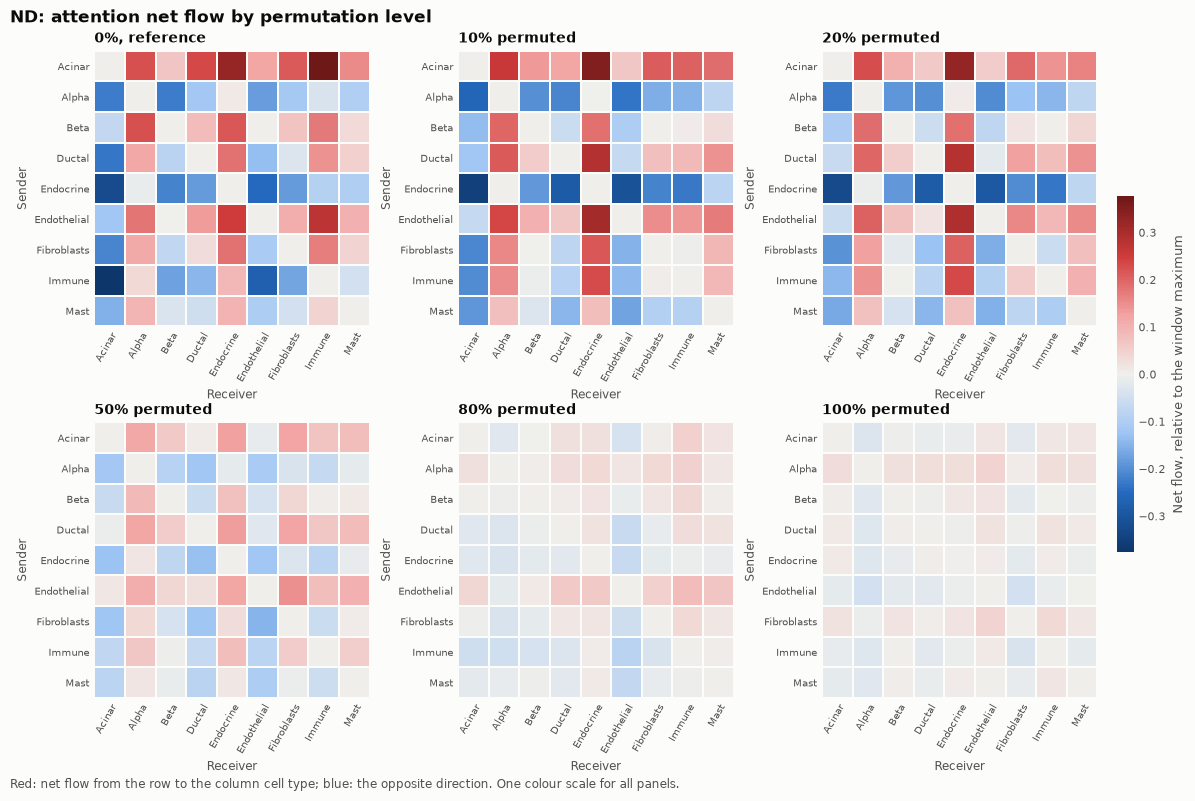

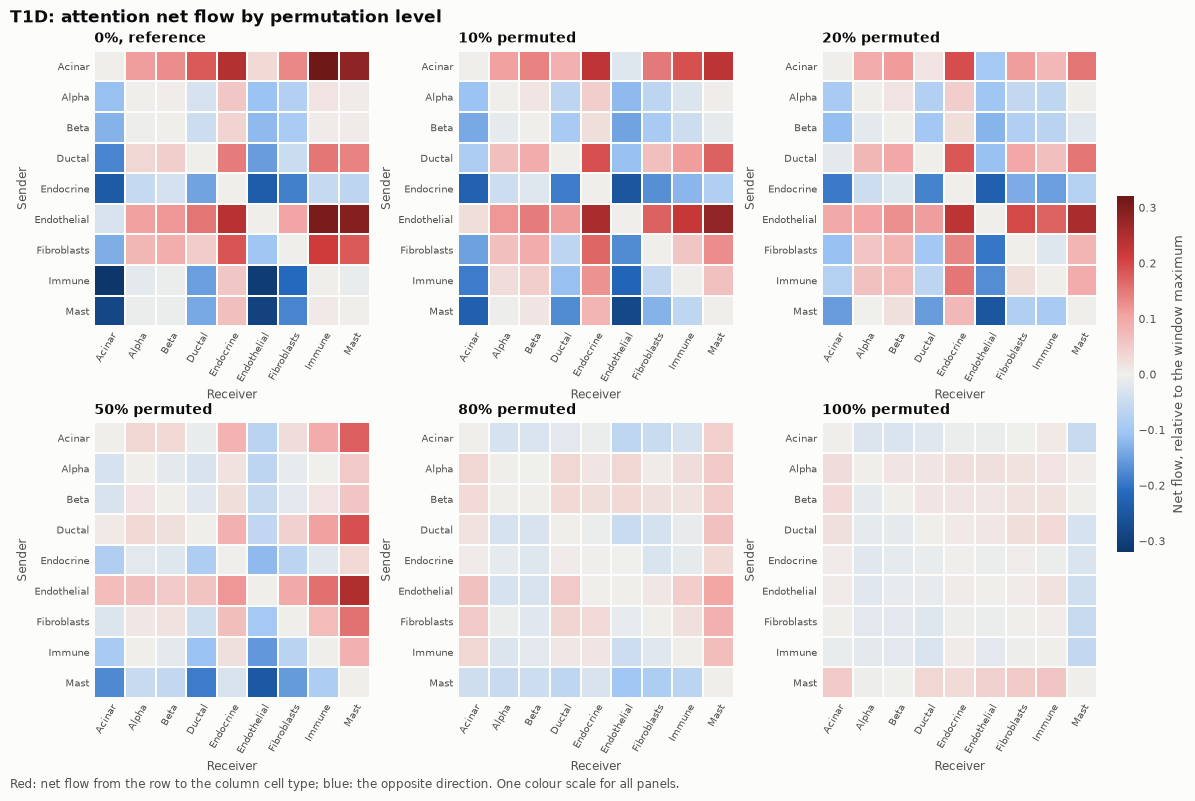

In [10]:
conditions = sorted({condition for by_condition in flows.values() for condition in by_condition})
colors = condition_colors(conditions)

for condition in conditions:
    matrices = {pct: flows[pct][condition]["mean"] for pct in LEVELS_PCT}
    limit = max(np.nanmax(np.abs(matrix.to_numpy(dtype=float))) for matrix in matrices.values()) or 1.0
    panels = [(f"{pct}% permuted" if pct else "0%, reference", matrix, None) for pct, matrix in matrices.items()]
    fig = plot_matrix_grid(
        panels,
        limit,
        "Net flow, relative to the window maximum",
        f"{condition}: attention net flow by permutation level",
        "Red: net flow from the row to the column cell type; blue: the opposite direction. One colour scale for all panels.",
    )
    show(fig, f"net_flow_{slug(condition)}")

### Reference minus permuted

The same matrices as differences to the unpermuted reference, per level. Stars mark entries where the difference exceeds 1.96, 2.58 or 3.29 times the spread of that entry across the FOVs of the permuted level. That is a normal approximation against the across-FOV spread, not an empirical permutation p-value. All panels of a figure share one colour scale.

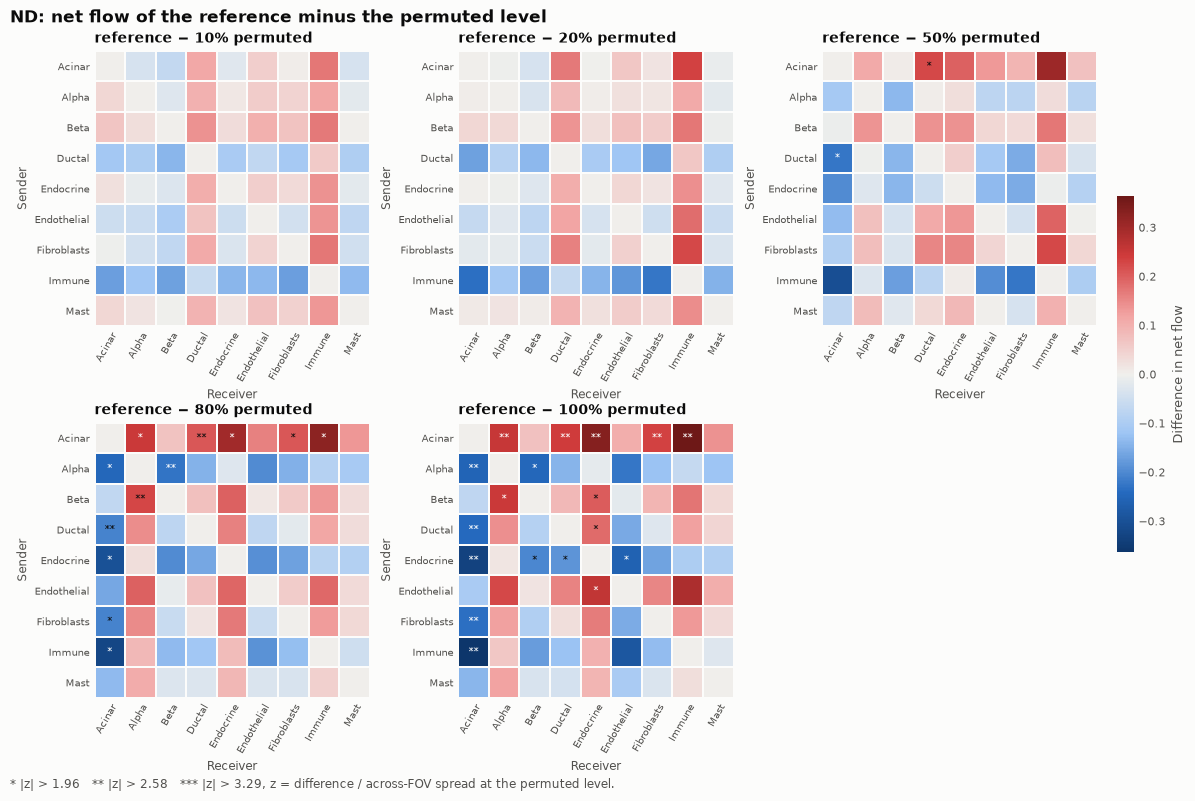

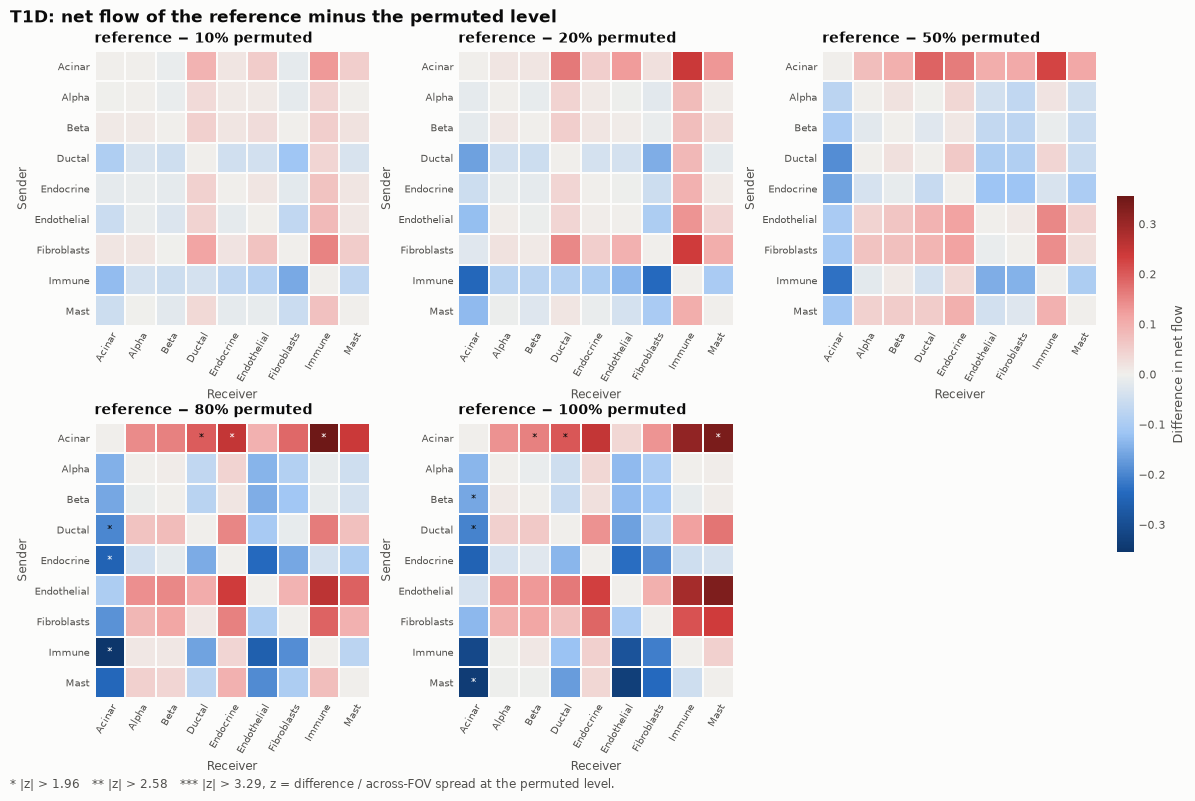

In [11]:
for condition in conditions:
    reference = flows[0][condition]["mean"]
    differences, marks = {}, {}
    for pct in LEVELS_PCT[1:]:
        level = flows[pct][condition]
        permuted = level["mean"].reindex(index=reference.index, columns=reference.columns)
        spread = level["std"].reindex(index=reference.index, columns=reference.columns)
        differences[pct] = reference - permuted
        marks[pct] = significance_marks(differences[pct] / (spread + EPS))
    if not differences:
        continue
    limit = max(np.nanmax(np.abs(difference.to_numpy(dtype=float))) for difference in differences.values()) or 1.0
    panels = [(f"reference − {pct}% permuted", differences[pct], marks[pct]) for pct in differences]
    fig = plot_matrix_grid(
        panels,
        limit,
        "Difference in net flow",
        f"{condition}: net flow of the reference minus the permuted level",
        "* |z| > 1.96   ** |z| > 2.58   *** |z| > 3.29, z = difference / across-FOV spread at the permuted level.",
    )
    show(fig, f"net_flow_difference_{slug(condition)}")

## Partial permutation: aggregate absolute net flow

For each cell type, the aggregate absolute net flow is the sum of the absolute entries in its row and its column of the net-flow matrix, halved so that the values of all cell types add up to the total absolute flow of the matrix. The figure has one panel per cell type, one line per condition and shared axes. A cell type whose flow rests on spatial structure should lose signal as the permutation grows; a flat line means the flow does not depend on where expression sits. The values are listed in the tables below the figure.

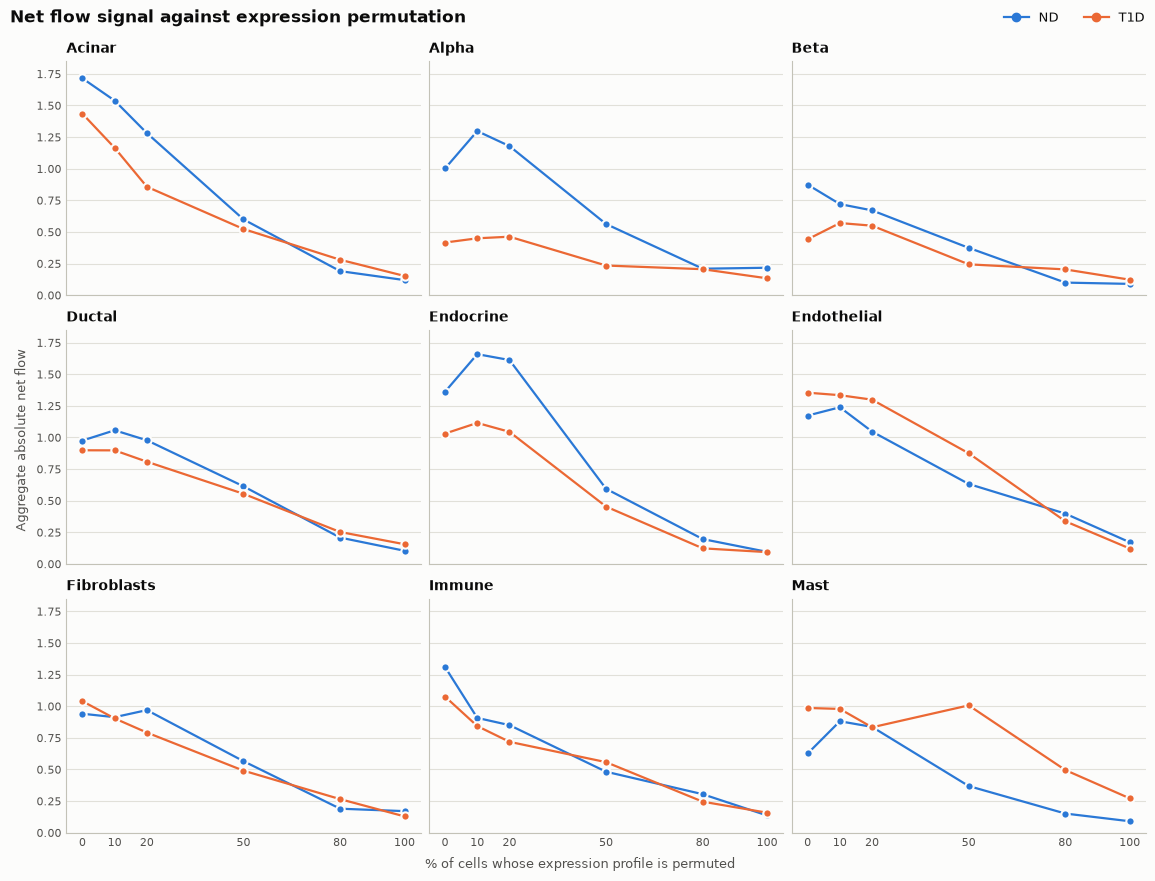

In [12]:
signal = pd.DataFrame(
    [
        {"level_pct": pct, "condition": condition, "cell_type": cell_type, "signal": float(value)}
        for pct, by_condition in flows.items()
        for condition, matrices in by_condition.items()
        for cell_type, value in cell_type_signal(matrices["mean"]).items()
    ]
)
signal.to_csv(RESULTS_DIR / "partial_permutation_signal.csv", index=False)


def plot_signal_curves(signal, colors):
    """One panel per cell type, one line per condition: aggregate absolute net flow against the permutation level."""
    cell_types = sorted(signal["cell_type"].unique())
    levels = sorted(signal["level_pct"].unique())
    n_cols = 3
    n_rows = math.ceil(len(cell_types) / n_cols)
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(3.6 * n_cols + 0.6, 2.5 * n_rows + 1.2),
        dpi=FIG_DPI,
        sharex=True,
        sharey=True,
        layout="constrained",
        squeeze=False,
    )
    for ax, cell_type in zip(axes.ravel(), cell_types, strict=False):
        for condition, color in colors.items():
            part = signal[(signal["cell_type"] == cell_type) & (signal["condition"] == condition)].sort_values(
                "level_pct"
            )
            ax.plot(
                part["level_pct"],
                part["signal"],
                color=color,
                linewidth=1.6,
                marker="o",
                markersize=6,
                markeredgecolor=SURFACE,
                markeredgewidth=1.5,
                solid_capstyle="round",
                solid_joinstyle="round",
            )
        ax.set_title(cell_type, loc="left", fontsize=10, fontweight="bold", color=INK)
        ax.set_xticks(levels)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, labelsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color(AXIS)
    axes[0, 0].set_ylim(0, signal["signal"].max() * 1.08)  # the axes are shared
    for ax in axes.ravel()[len(cell_types) :]:
        ax.set_visible(False)
    fig.supxlabel("% of cells whose expression profile is permuted", fontsize=9, color=INK_2)
    fig.supylabel("Aggregate absolute net flow", fontsize=9, color=INK_2)
    handles = [
        Line2D([], [], color=color, linewidth=1.6, marker="o", markersize=6, label=condition)
        for condition, color in colors.items()
    ]
    fig.legend(handles=handles, loc="outside upper right", ncol=len(handles), frameon=False, fontsize=9)
    fig.suptitle("Net flow signal against expression permutation", x=0.0, ha="left", fontsize=12, fontweight="bold")
    return fig


show(plot_signal_curves(signal, colors), "partial_permutation_signal")

In [13]:
# The same values as a table: aggregate absolute net flow per cell type (rows) and permutation level (columns).
for condition in conditions:
    table = signal[signal["condition"] == condition].pivot(index="cell_type", columns="level_pct", values="signal")
    table.columns = [f"{pct}%" for pct in table.columns]
    display(table.rename_axis(index=condition).round(3))

,0%,10%,20%,50%,80%,100%
ND,,,,,,
Acinar,1.715,1.539,1.282,0.599,0.190,0.119
Alpha,1.002,1.298,1.179,0.563,0.209,0.217
Beta,0.874,0.720,0.671,0.374,0.100,0.089
Ductal,0.976,1.057,0.978,0.614,0.208,0.104
Endocrine,1.362,1.659,1.612,0.594,0.197,0.095
Endothelial,1.173,1.239,1.047,0.632,0.398,0.171
Fibroblasts,0.941,0.913,0.969,0.565,0.190,0.170
Immune,1.310,0.908,0.851,0.482,0.304,0.136
Mast,0.626,0.881,0.837,0.369,0.151,0.090


,0%,10%,20%,50%,80%,100%
T1D,,,,,,
Acinar,1.435,1.165,0.857,0.523,0.280,0.152
Alpha,0.416,0.450,0.463,0.235,0.206,0.134
Beta,0.442,0.571,0.550,0.244,0.204,0.123
Ductal,0.899,0.898,0.808,0.555,0.253,0.156
Endocrine,1.031,1.115,1.045,0.453,0.123,0.094
Endothelial,1.354,1.334,1.299,0.875,0.338,0.122
Fibroblasts,1.040,0.903,0.792,0.491,0.265,0.129
Immune,1.076,0.843,0.719,0.558,0.245,0.158
Mast,0.986,0.979,0.833,1.007,0.495,0.272


## Reading the results and their limits

- **One model and one seed per level.** Differences between neighbouring levels contain training noise as well as the effect of the data. The stars compare the reference with the spread between FOVs at the permuted level; they are a screening heuristic.
- **Which cells were permuted** is set by `SHUFFLE_SPLITS` and printed above. If held-out slides stay unpermuted, they are averaged into every level and damp the apparent effect, because the flow is aggregated over all cells whatever their split.
- **Flows are relative.** Every window is divided by its largest absolute entry before averaging, so a window with weak attention structure counts as much as a strong one. The aggregate absolute net flow therefore reflects how many cell-type pairs carry flow relative to the strongest pair of a window, and how consistently windows and FOVs agree on its direction; it is not a measure of attention strength.
- **The whole window is in reach.** Without a long-range mask the transformer attends to every other cell of a window, so the flow mixes short- and long-range pairs.
- **Windows.** The flow is aggregated over the windows the attention is indexed by (named in the training summary above); the windows of the other partition only add training examples.
- **A fixed training budget** is the same for every level, so a level that is harder to fit is not trained for longer. The training summary above lists the validation loss each level reached.